# Dana's Bakery: orders with Python and LangGraph

This beginner-friendly notebook turns an order into a friendly confirmation or
cancellation using six ordinary Python functions connected by a **StateGraph**.
All business decisions and messages are deterministic. No LLM, OpenAI SDK, API
key, AI API, paid service, or Instagram integration is used.

**In Google Colab:** upload `dana_bakery.ipynb`, choose a Python runtime, and select
**Runtime → Run all**. A CPU runtime is sufficient. The setup cell installs the
required package if needed. Run the cells in order; then edit the example order.
This file was prepared for Colab; local validation is documented in `README.md`.
No live Colab execution is claimed.

Each order uses the same stock snapshot independently. Substitutions are
**automatically accepted** because the input has no customer-confirmation field.
Rejected results use `item=None`, `delivery="pickup"`, and `total=0`; pickup is a
required output default, not a pickup booking for a cancelled order.

## 1. Business rules

| Product | Unit price (NIS) | Available stock |
| --- | ---: | ---: |
| challah | 18 | 10 |
| babka | 45 | 0 |
| rugelach | 30 | 3 |
| sourdough | 25 | 4 |

Reject croissant/croissants (discontinued) and any unknown product. Quantities
must be positive Python integers: `2` is valid; `0`, `-1`, `2.0`, `"2"`, `True`,
and `None` are invalid. All four fields are required. Item, day, and city must be
strings; day must be a full English weekday name. Surrounding spaces and case
are ignored; a whitespace-only city means pickup.

An insufficient original product may move **forward only** along
**babka → rugelach → sourdough → challah**, checking at most **two** alternatives.
Every candidate must cover the **entire unchanged quantity**. There is no wrap,
backtracking, splitting, or partial fill. Babka × 5 must be cancelled after
rugelach and sourdough fail, even though challah stock would suffice.

**Avi's final correction:** discount baked goods by **15%** only when their
subtotal is **strictly greater than 150 NIS** and the day is **not Friday**.
The earlier 10% over 200 rule is superseded and is never implemented.
Apply the discount before adding delivery; never discount the delivery fee.

Empty city → free pickup. Jerusalem → delivery for 20 NIS. Any other city →
free pickup with a clear explanation. Prices and discounts use `Decimal` and
two-decimal `ROUND_HALF_UP` rounding; the public total is a numeric NIS value.

## 2. Plan the graph before building it

The **state** is the shared order worksheet. Each **node** is a function that
returns only the fields it changes. An **edge** says which function runs next.

| Node | Responsibility |
| --- | --- |
| `validate_order` | Validate raw inputs, normalize text, initialize this order |
| `check_stock` | Check the current candidate against the full quantity |
| `select_alternative` | Advance one product and count the alternative |
| `calculate_price` | Use the final product's price and Avi's discount rule |
| `decide_delivery` | Choose delivery/pickup and add the delivery fee |
| `generate_message` | Build a friendly template and finalize the result |

**Fixed edges:** `START → validate_order`, `select_alternative → check_stock`,
and `calculate_price → decide_delivery → generate_message → END`.

**Conditional edges:** after validation, go to `check_stock` if valid, otherwise
to `generate_message`. After checking stock, go to `calculate_price` if enough
stock exists, to `select_alternative` if another attempt is allowed, otherwise
to `generate_message` for cancellation.

The repeating path is `check_stock → select_alternative → check_stock`.
Every selection increments `alternatives_tried`. Both the router and selection
node guard the two-alternative limit. The product index always increases; no
third alternative or infinite loop is possible. Every branch reaches `END`.

There is no checkpointer or stock mutation: each invocation starts a new order.
The typed output schema exposes exactly the six requested result fields.

In [1]:
# Install the version used for local validation only if it is not already present.
# %pip installs into the active Colab/Jupyter kernel, not a different Python.
from importlib.metadata import PackageNotFoundError, version

LANGGRAPH_VERSION = "1.2.20"
try:
    installed_version = version("langgraph")
except PackageNotFoundError:
    installed_version = None

if installed_version != LANGGRAPH_VERSION:
    %pip install -q "langgraph==1.2.20"

print("LangGraph version:", version("langgraph"))

LangGraph version: 1.2.20


In [2]:
import operator
import os
from decimal import Decimal, ROUND_HALF_UP
from pprint import pprint
from typing import Annotated, Literal, TypedDict

# Explicitly disable optional tracing even if the runtime has tracing enabled.
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"

from IPython.display import Image, display
from langgraph.graph import END, START, StateGraph

CATALOG = {
    "challah": {"price": Decimal("18.00"), "stock": 10},
    "babka": {"price": Decimal("45.00"), "stock": 0},
    "rugelach": {"price": Decimal("30.00"), "stock": 3},
    "sourdough": {"price": Decimal("25.00"), "stock": 4},
}
SUBSTITUTION_SEQUENCE = ("babka", "rugelach", "sourdough", "challah")
DISCONTINUED = {"croissant", "croissants"}
WEEKDAYS = {"monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"}
MAX_ALTERNATIVES = 2
DISCOUNT_THRESHOLD = Decimal("150.00")
DISCOUNT_RATE = Decimal("0.15")
DELIVERY_FEE = Decimal("20.00")
ZERO = Decimal("0.00")


def money(amount: Decimal) -> Decimal:
    '''Round money consistently to the nearest agora (0.01 NIS).'''
    return amount.quantize(Decimal("0.01"), rounding=ROUND_HALF_UP)


def normalize_text(value: str) -> str:
    return value.strip().casefold()

## 3. Define the typed state

`OrderInput` contains untrusted values, so its fields are typed as `object` until
validation. `total=False` permits missing fields to reach our polite validation
node instead of raising a schema error. `TypedDict` documents shape; it does not
perform runtime validation. Our node does that explicitly.

`OrderState` adds normalized values, the current candidate, attempt count,
availability, amounts, and a rejection reason. `OrderResult` describes the public
output: `status`, `item`, `delivery`, `total`, `message`, and `steps`.

`steps: Annotated[list[str], operator.add]` is an **append reducer**. Each executed
node returns a one-element list with its own name. LangGraph appends the update
instead of overwriting earlier history. Repeated visits remain visible in time
order. This graph is sequential, so chronological order is unambiguous. Router
functions and virtual START/END markers are control flow, not processing nodes;
they do not add entries. Do not pass your own `steps` in an input order.

In [3]:
class OrderInput(TypedDict, total=False):
    item: object
    quantity: object
    day: object
    city: object


class OrderState(OrderInput, total=False):
    # These fields exist only after validate_order has run.
    requested_item: str
    validated_quantity: int
    normalized_day: str
    normalized_city: str
    city_label: str
    candidate_item: str
    candidate_index: int
    alternatives_tried: int
    checked_items: list[str]
    valid: bool
    available: bool
    rejection_reason: str
    unit_price: Decimal
    subtotal: Decimal
    discount: Decimal
    goods_total: Decimal
    delivery_fee: Decimal
    pickup_changed: bool
    status: Literal["accepted", "rejected"]
    delivery: Literal["pickup", "delivery"]
    total: float
    message: str
    steps: Annotated[list[str], operator.add]


class OrderResult(TypedDict):
    status: Literal["accepted", "rejected"]
    item: str | None
    delivery: Literal["pickup", "delivery"]
    total: float
    message: str
    steps: list[str]

## 4. Validate the input

Check the item first, then quantity, weekday, and city. The first invalid field
produces a helpful reason. A default rejected result is initialized immediately;
only a successfully priced order changes to accepted. We deliberately exclude
booleans using `type(quantity) is int`, because `isinstance(True, int)` is true.

In [4]:
def validate_order(state: OrderState) -> dict:
    raw_item = state.get("item")
    quantity = state.get("quantity")
    raw_day = state.get("day")
    raw_city = state.get("city")

    update = {
        "status": "rejected", "item": None, "delivery": "pickup", "total": 0.0,
        "valid": False, "available": False, "alternatives_tried": 0,
        "checked_items": [], "rejection_reason": "", "pickup_changed": False,
        "steps": ["validate_order"],
    }
    if not isinstance(raw_item, str) or not raw_item.strip():
        reason = "Please choose an item from our bakery menu."
    elif normalize_text(raw_item) in DISCONTINUED:
        reason = "Croissants have been discontinued and are no longer available."
    elif normalize_text(raw_item) not in CATALOG:
        reason = f"We don't have {raw_item.strip()!r} on our menu."
    elif type(quantity) is not int or quantity <= 0:
        reason = "Please enter a positive whole-number quantity, such as 1 or 2."
    elif not isinstance(raw_day, str) or normalize_text(raw_day) not in WEEKDAYS:
        reason = "Please provide a full weekday name, such as Thursday or Friday."
    elif not isinstance(raw_city, str):
        reason = "Please provide a city name, or an empty string for free pickup."
    else:
        item = normalize_text(raw_item)
        update.update({
            "valid": True,
            "requested_item": item,
            "validated_quantity": quantity,
            "normalized_day": normalize_text(raw_day),
            "normalized_city": normalize_text(raw_city),
            "city_label": raw_city.strip(),
            "candidate_item": item,
            "candidate_index": SUBSTITUTION_SEQUENCE.index(item),
        })
        return update

    update["rejection_reason"] = reason
    return update

## 5. Check stock and select alternatives

`check_stock` always compares stock with the **original quantity** and records
the checked product. It never reduces stock. `select_alternative` advances by
exactly one position. The stock router (defined below) decides whether to use
that candidate, try another, or cancel. The guard in the selection node is an
additional protection; normal graph routing prevents it from being triggered.

In [5]:
def check_stock(state: OrderState) -> dict:
    item = state["candidate_item"]
    return {
        "available": CATALOG[item]["stock"] >= state["validated_quantity"],
        "checked_items": state["checked_items"] + [item],
        "steps": ["check_stock"],
    }


def select_alternative(state: OrderState) -> dict:
    next_index = state["candidate_index"] + 1
    if state["alternatives_tried"] >= MAX_ALTERNATIVES:
        raise RuntimeError("Graph routing attempted more than two alternatives.")
    if next_index >= len(SUBSTITUTION_SEQUENCE):
        raise RuntimeError("Graph routing attempted to move past the final product.")

    return {
        "candidate_index": next_index,
        "candidate_item": SUBSTITUTION_SEQUENCE[next_index],
        "alternatives_tried": state["alternatives_tried"] + 1,
        "steps": ["select_alternative"],
    }

## 6. Calculate price, then decide delivery

These are separate nodes. The pricing node uses the **selected product's price**
for the full quantity. It applies only Avi's rule. The delivery node adds either
20 NIS or zero **after** the discounted baked-goods amount is calculated.
All intermediate money stays `Decimal`; the final public number is a float.

In [6]:
def calculate_price(state: OrderState) -> dict:
    item = state["candidate_item"]
    unit_price = CATALOG[item]["price"]
    subtotal = money(unit_price * state["validated_quantity"])
    eligible = subtotal > DISCOUNT_THRESHOLD and state["normalized_day"] != "friday"
    discount = money(subtotal * DISCOUNT_RATE) if eligible else ZERO
    return {
        "status": "accepted",
        "item": item,
        "unit_price": unit_price,
        "subtotal": subtotal,
        "discount": discount,
        "goods_total": money(subtotal - discount),
        "steps": ["calculate_price"],
    }


def decide_delivery(state: OrderState) -> dict:
    city = state["normalized_city"]
    delivery = "delivery" if city == "jerusalem" else "pickup"
    fee = DELIVERY_FEE if delivery == "delivery" else ZERO
    return {
        "delivery": delivery,
        "delivery_fee": fee,
        "pickup_changed": bool(city) and city != "jerusalem",
        "total": float(money(state["goods_total"] + fee)),
        "steps": ["decide_delivery"],
    }

## 7. Generate a friendly message with Python templates

There is one message node for both outcomes. It explains invalid input or stock
cancellation; accepted orders explain replacements, prices, discounts, and
pickup changes when applicable. The templates use only Python strings.

In [7]:
def generate_message(state: OrderState) -> dict:
    if state["status"] == "rejected":
        if not state["valid"]:
            reason = state["rejection_reason"]
        else:
            requested = state["requested_item"]
            quantity = state["validated_quantity"]
            alternatives = state["checked_items"][1:]
            reason = f"We don't have enough {requested} for all {quantity} requested units. "
            if alternatives:
                reason += (
                    f"We checked {' and '.join(alternatives)}, but neither can cover "
                    "the full quantity. "
                    if len(alternatives) == 2 else
                    f"We checked {alternatives[0]}, but it cannot cover the full quantity. "
                )
            if state["alternatives_tried"] == MAX_ALTERNATIVES:
                reason += "We've reached our limit of two alternatives."
            else:
                reason += "There are no further forward substitutions available."

        return {
            "status": "rejected", "item": None, "delivery": "pickup", "total": 0.0,
            "message": (
                f"Hi from Dana's Bakery! We're sorry, your order has been cancelled. "
                f"{reason} No payment is due. We'd love to help with another order!"
            ),
            "steps": ["generate_message"],
        }

    item = state["candidate_item"]
    quantity = state["validated_quantity"]
    parts = ["Hi from Dana's Bakery! Thanks for your order."]
    if item != state["requested_item"]:
        parts.append(
            f"We don't have enough {state['requested_item']}, so we've automatically "
            f"replaced it with {item} for the same quantity of {quantity}. "
            f"Your replacement costs {state['unit_price']:.2f} NIS per unit."
        )
    parts.append(
        f"Your order is confirmed: {quantity} x {item} at "
        f"{state['unit_price']:.2f} NIS each. "
        f"Baked-goods subtotal: {state['subtotal']:.2f} NIS."
    )
    if state["discount"] > ZERO:
        parts.append(
            f"Your 15% baked-goods discount saves {state['discount']:.2f} NIS; "
            f"baked goods after discount: {state['goods_total']:.2f} NIS."
        )
    elif state["normalized_day"] == "friday" and state["subtotal"] > DISCOUNT_THRESHOLD:
        parts.append("The baked-goods discount is not available on Friday.")

    if state["delivery"] == "delivery":
        parts.append("Delivery to Jerusalem: 20.00 NIS.")
    elif state["pickup_changed"]:
        parts.append(
            f"We currently deliver only within Jerusalem, so we've changed delivery "
            f"to {state['city_label']} to free pickup at the bakery."
        )
    else:
        parts.append("Free pickup at the bakery is selected.")

    parts.append(f"Total to pay: {state['total']:.2f} NIS. We look forward to seeing you!")
    return {"message": "\n\n".join(parts), "steps": ["generate_message"]}

## 8. Connect and compile the real graph

Router functions return a route label; explicit path maps connect that label to
the destination node. `after_stock` checks availability first, then the attempt
limit and the existence of a forward candidate. It cannot send the graph to a
third alternative. Failed validation and exhausted stock both use the message
node and its fixed edge to `END`.

The `input_schema` filters inputs to the four order fields. The `output_schema`
filters results to the six requested keys, keeping calculation details internal.
`compile()` produces the `graph` that we invoke and draw below.

In [8]:
def after_validation(state: OrderState) -> Literal["valid", "invalid"]:
    return "valid" if state["valid"] else "invalid"


def after_stock(state: OrderState) -> Literal["available", "try_next", "unavailable"]:
    if state["available"]:
        return "available"
    has_next = state["candidate_index"] + 1 < len(SUBSTITUTION_SEQUENCE)
    if state["alternatives_tried"] < MAX_ALTERNATIVES and has_next:
        return "try_next"
    return "unavailable"


builder = StateGraph(OrderState, input_schema=OrderInput, output_schema=OrderResult)
builder.add_node("validate_order", validate_order)
builder.add_node("check_stock", check_stock)
builder.add_node("select_alternative", select_alternative)
builder.add_node("calculate_price", calculate_price)
builder.add_node("decide_delivery", decide_delivery)
builder.add_node("generate_message", generate_message)

builder.add_edge(START, "validate_order")
builder.add_conditional_edges("validate_order", after_validation, {
    "valid": "check_stock",
    "invalid": "generate_message",
})
builder.add_conditional_edges("check_stock", after_stock, {
    "available": "calculate_price",
    "try_next": "select_alternative",
    "unavailable": "generate_message",
})
builder.add_edge("select_alternative", "check_stock")
builder.add_edge("calculate_price", "decide_delivery")
builder.add_edge("decide_delivery", "generate_message")
builder.add_edge("generate_message", END)

graph = builder.compile()
print("Compiled: six functional nodes, two conditional decisions, one bounded loop.")

Compiled: six functional nodes, two conditional decisions, one bounded loop.


## 9. Draw the actual compiled graph

This calls `draw_mermaid_png()` on **this compiled graph**, rather than a manually
written diagram. Its default free Mermaid image renderer requires internet
access and receives only the graph structure. It is not an AI API; order
processing itself runs locally. If the renderer is temporarily unavailable, the
cell prints the actual compiled graph's Mermaid text and lets the tests run.
Re-run this cell when internet access is available to display the PNG.

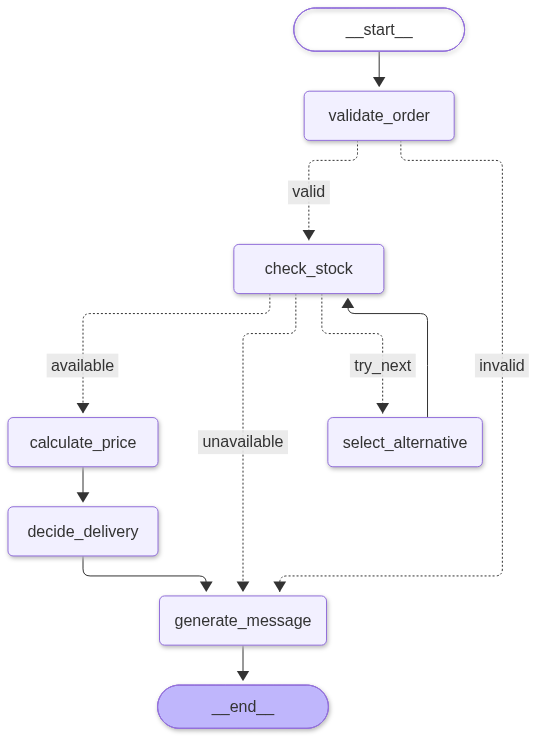

In [9]:
compiled_diagram = graph.get_graph()
try:
    graph_png = compiled_diagram.draw_mermaid_png()
except Exception as error:
    # Rendering is optional for processing; business/test errors are not caught.
    print(f"PNG renderer unavailable ({type(error).__name__}).")
    print("The compiled graph's Mermaid source is shown below. Re-run this cell to retry.")
    print(compiled_diagram.draw_mermaid())
else:
    display(Image(graph_png))

## 10. Process an order

Babka × 2 is out of stock. The first alternative is rugelach, which has three
units available. Charge 2 × 30 = 60 NIS, then add Jerusalem delivery of 20 NIS:
**80 NIS total**, with no discount. The quantity stays two.

In [10]:
result = graph.invoke({"item": "babka", "quantity": 2, "day": "Thursday", "city": "Jerusalem"})
pprint(result, sort_dicts=False)
print("\nCustomer message:\n")
print(result["message"])

assert result["status"] == "accepted"
assert result["item"] == "rugelach"
assert result["delivery"] == "delivery"
assert result["total"] == 80.0
assert result["steps"] == [
    "validate_order", "check_stock", "select_alternative", "check_stock",
    "calculate_price", "decide_delivery", "generate_message",
]

{'status': 'accepted',
 'item': 'rugelach',
 'delivery': 'delivery',
 'total': 80.0,
 'message': "Hi from Dana's Bakery! Thanks for your order.\n"
            '\n'
            "We don't have enough babka, so we've automatically replaced it "
            'with rugelach for the same quantity of 2. Your replacement costs '
            '30.00 NIS per unit.\n'
            '\n'
            'Your order is confirmed: 2 x rugelach at 30.00 NIS each. '
            'Baked-goods subtotal: 60.00 NIS.\n'
            '\n'
            'Delivery to Jerusalem: 20.00 NIS.\n'
            '\n'
            'Total to pay: 80.00 NIS. We look forward to seeing you!',
 'steps': ['validate_order',
           'check_stock',
           'select_alternative',
           'check_stock',
           'calculate_price',
           'decide_delivery',
           'generate_message']}

Customer message:

Hi from Dana's Bakery! Thanks for your order.

We don't have enough babka, so we've automatically replaced it with rugelach

## 11. Test real orders and expected paths

The table below contains more than ten independent test orders. Expected values
are written explicitly; they are not calculated from the implementation under
test. Every result is checked for all six required keys, values, types, friendly
message details, and the complete chronological node history. `attempts=None`
means validation failed before any stock check.

Discount examples: challah × 9 on Thursday gives 162 − 24.30 = **137.70 NIS**
(or **157.70** with Jerusalem delivery). On Friday, the same delivery order is
**182 NIS**. Babka × 4 uses the second alternative (sourdough) for **100 NIS**.
Rugelach × 5 uses its second alternative (challah) for **90 NIS**.

In [11]:
def order(item="challah", quantity=1, day="Thursday", city=""):
    return {"item": item, "quantity": quantity, "day": day, "city": city}


# name, input, status, actual item, delivery, total, alternative count, message snippet
TEST_CASES = [
    ("original available", order(quantity=2), "accepted", "challah", "pickup", 36.0, 0, "2 x challah"),
    ("full stock available", order(quantity=10), "accepted", "challah", "pickup", 153.0, 0, "15%"),
    ("first substitute", order("babka", 2, city="Jerusalem"), "accepted", "rugelach", "delivery", 80.0, 1, "automatically"),
    ("second substitute", order("babka", 4), "accepted", "sourdough", "pickup", 100.0, 2, "same quantity of 4"),
    ("never third substitute", order("babka", 5), "rejected", None, "pickup", 0.0, 2, "limit of two"),
    ("no candidate can fill", order("babka", 11, city="Jerusalem"), "rejected", None, "pickup", 0.0, 2, "full quantity"),
    ("forward from rugelach", order("rugelach", 4), "accepted", "sourdough", "pickup", 100.0, 1, "25.00 NIS per unit"),
    ("second from rugelach", order("rugelach", 5), "accepted", "challah", "pickup", 90.0, 2, "18.00 NIS per unit"),
    ("one forward option", order("sourdough", 5), "accepted", "challah", "pickup", 90.0, 1, "replaced"),
    ("end of sequence", order("challah", 11), "rejected", None, "pickup", 0.0, 0, "no further forward"),
    ("one alternative fails", order("sourdough", 11), "rejected", None, "pickup", 0.0, 1, "checked challah"),
    ("rugelach stock equality", order("rugelach", 3), "accepted", "rugelach", "pickup", 90.0, 0, "confirmed"),
    ("sourdough stock equality", order("sourdough", 4), "accepted", "sourdough", "pickup", 100.0, 0, "confirmed"),
    ("weekday discount", order(quantity=9), "accepted", "challah", "pickup", 137.7, 0, "24.30 NIS"),
    ("discount then delivery", order(quantity=9, city="Jerusalem"), "accepted", "challah", "delivery", 157.7, 0, "20.00 NIS"),
    ("Friday excludes discount", order(quantity=9, day="Friday", city="Jerusalem"), "accepted", "challah", "delivery", 182.0, 0, "not available on Friday"),
    ("below discount threshold", order(quantity=8), "accepted", "challah", "pickup", 144.0, 0, "144.00 NIS"),
    ("substitution discount", order("sourdough", 9), "accepted", "challah", "pickup", 137.7, 1, "15%"),
    ("Jerusalem delivery", order("sourdough", 1, city="Jerusalem"), "accepted", "sourdough", "delivery", 45.0, 0, "Delivery to Jerusalem"),
    ("empty city pickup", order("rugelach", 1), "accepted", "rugelach", "pickup", 30.0, 0, "Free pickup"),
    ("other city pickup", order(city="Tel Aviv"), "accepted", "challah", "pickup", 18.0, 0, "changed delivery to Tel Aviv"),
    ("case and whitespace", order("  ChAlLaH ", 9, " thURsday ", " jErUsAlEm "), "accepted", "challah", "delivery", 157.7, 0, "15%"),
    ("Friday normalization", order(quantity=9, day=" fRiDaY "), "accepted", "challah", "pickup", 162.0, 0, "Friday"),
    ("whitespace city", order(city="   "), "accepted", "challah", "pickup", 18.0, 0, "Free pickup"),
    ("other city normalization", order(city="  hAiFa  "), "accepted", "challah", "pickup", 18.0, 0, "free pickup"),
    ("croissant discontinued", order("croissant"), "rejected", None, "pickup", 0.0, None, "discontinued"),
    ("croissants normalized", order("  CROISSANTS  "), "rejected", None, "pickup", 0.0, None, "discontinued"),
    ("unknown product", order("muffin"), "rejected", None, "pickup", 0.0, None, "menu"),
    ("empty item", order("  "), "rejected", None, "pickup", 0.0, None, "choose an item"),
    ("invalid item type", order(None), "rejected", None, "pickup", 0.0, None, "choose an item"),
    ("zero quantity", order(quantity=0), "rejected", None, "pickup", 0.0, None, "positive whole-number"),
    ("negative quantity", order(quantity=-1), "rejected", None, "pickup", 0.0, None, "positive whole-number"),
    ("fractional quantity", order(quantity=1.5), "rejected", None, "pickup", 0.0, None, "positive whole-number"),
    ("integral float quantity", order(quantity=2.0), "rejected", None, "pickup", 0.0, None, "positive whole-number"),
    ("string quantity", order(quantity="2"), "rejected", None, "pickup", 0.0, None, "positive whole-number"),
    ("boolean quantity", order(quantity=True), "rejected", None, "pickup", 0.0, None, "positive whole-number"),
    ("null quantity", order(quantity=None), "rejected", None, "pickup", 0.0, None, "positive whole-number"),
    ("list quantity", order(quantity=[2]), "rejected", None, "pickup", 0.0, None, "positive whole-number"),
    ("invalid weekday", order(day="Fryday"), "rejected", None, "pickup", 0.0, None, "weekday"),
    ("invalid day type", order(day=None), "rejected", None, "pickup", 0.0, None, "weekday"),
    ("invalid city type", order(city=None), "rejected", None, "pickup", 0.0, None, "city name"),
    ("missing fields", {}, "rejected", None, "pickup", 0.0, None, "choose an item"),
    ("missing quantity", {"item": "challah", "day": "Thursday", "city": ""}, "rejected", None, "pickup", 0.0, None, "positive whole-number"),
    ("missing day", {"item": "challah", "quantity": 1, "city": ""}, "rejected", None, "pickup", 0.0, None, "weekday"),
    ("missing city", {"item": "challah", "quantity": 1, "day": "Thursday"}, "rejected", None, "pickup", 0.0, None, "city name"),
]

In [12]:
REQUIRED_KEYS = {"status", "item", "delivery", "total", "message", "steps"}


def expected_steps(status, attempts):
    if attempts is None:
        return ["validate_order", "generate_message"]
    history = ["validate_order", "check_stock"]
    history += ["select_alternative", "check_stock"] * attempts
    if status == "accepted":
        history += ["calculate_price", "decide_delivery"]
    return history + ["generate_message"]


test_results = {}
stock_before = {item: data["stock"] for item, data in CATALOG.items()}
for name, data, status, item, delivery, total, attempts, snippet in TEST_CASES:
    output = graph.invoke(data)
    test_results[name] = output
    assert REQUIRED_KEYS <= output.keys(), (name, "missing required keys")
    assert set(output) == REQUIRED_KEYS, (name, "unexpected output fields")
    assert output["status"] == status, (name, output)
    assert output["item"] == item, (name, output)
    assert output["delivery"] == delivery, (name, output)
    assert Decimal(str(output["total"])) == Decimal(str(total)), (name, output)
    assert type(output["total"]) in (int, float), name
    assert isinstance(output["message"], str) and output["message"].strip(), name
    assert snippet.casefold() in output["message"].casefold(), (name, output["message"])
    assert isinstance(output["steps"], list), name
    assert all(isinstance(step, str) for step in output["steps"]), name
    assert output["steps"] == expected_steps(status, attempts), (name, output["steps"])
    assert output["steps"].count("select_alternative") <= 2, name
    if status == "rejected":
        assert output["item"] is None and output["total"] == 0, name
        assert output["delivery"] == "pickup", name
        assert "cancelled" in output["message"] and "No payment is due" in output["message"], name
    else:
        assert f"{data['quantity']} x {item}" in output["message"], name

assert {item: data["stock"] for item, data in CATALOG.items()} == stock_before
assert graph.invoke(order(quantity=10)) == graph.invoke(order(quantity=10))
assert graph.invoke(order("babka", 5))["status"] == "rejected"  # Challah cannot be a third try.

print(f"PASS: {len(TEST_CASES)} test orders; all six output keys and full paths verified.")
print("PASS: unchanged stock, independent repeated orders, and strict two-alternative limit.")
for name in ("first substitute", "second substitute", "never third substitute", "discount then delivery"):
    output = test_results[name]
    print(f"{name:24} {output['status']:8} item={str(output['item']):10} total={output['total']:.2f} NIS")

PASS: 45 test orders; all six output keys and full paths verified.
PASS: unchanged stock, independent repeated orders, and strict two-alternative limit.
first substitute         accepted item=rugelach   total=80.00 NIS
second substitute        accepted item=sourdough  total=100.00 NIS
never third substitute   rejected item=None       total=0.00 NIS
discount then delivery   accepted item=challah    total=157.70 NIS


## 12. Verify discount boundaries and recorded execution

The current stock snapshot cannot fulfill a product subtotal of exactly 150 NIS
or above 200 NIS. To test those **pricing rules in isolation**, call the pricing
node directly with small synthetic pricing states. These checks do not bypass
stock validation for any real order or change the catalog.

We also compare `steps` with the actual node updates emitted by `graph.stream`
for representative valid, invalid, substituted, and cancelled paths. This checks
that the history really records executed nodes rather than a predicted path.

In [13]:
# Isolated pricing checks, not accepted stock-validated orders.
boundary = calculate_price({
    "candidate_item": "sourdough", "validated_quantity": 6, "normalized_day": "thursday",
})
assert boundary["subtotal"] == Decimal("150.00")
assert boundary["discount"] == ZERO
assert boundary["goods_total"] == Decimal("150.00")

above_200 = calculate_price({
    "candidate_item": "sourdough", "validated_quantity": 10, "normalized_day": "thursday",
})
assert above_200["subtotal"] == Decimal("250.00")
assert above_200["discount"] == Decimal("37.50")  # 15%, never the superseded 10%.
assert above_200["goods_total"] == Decimal("212.50")

friday = calculate_price({
    "candidate_item": "sourdough", "validated_quantity": 10, "normalized_day": "friday",
})
assert friday["discount"] == ZERO
assert friday["goods_total"] == Decimal("250.00")
assert money(Decimal("1.005")) == Decimal("1.01")

for data in (order(), order("muffin"), order("babka", 4), order("babka", 5)):
    executed_nodes = []
    logged_steps = []
    for event in graph.stream(data, stream_mode="updates"):
        for node_name, update in event.items():
            executed_nodes.append(node_name)
            assert update["steps"] == [node_name], (node_name, update)
            logged_steps.extend(update["steps"])
    assert logged_steps == executed_nodes
    assert graph.invoke(data)["steps"] == executed_nodes

print("PASS: exact 150 threshold, 15% above 200, Friday exclusion, and money rounding.")
print("PASS: recorded steps match actual streamed execution for four representative paths.")

PASS: exact 150 threshold, 15% above 200, Friday exclusion, and money rounding.
PASS: recorded steps match actual streamed execution for four representative paths.


## 13. Try your own order

Edit only the four input fields below and run the cell. `item` in the result is
the product actually sold; check the message and `steps` to see what happened.
All invocations keep using the original stock snapshot.

This is a small teaching workflow, not a payment or inventory reservation system.
For the full specification, assumptions, and prompt-revision notes, see `prompt.md`.

Official references: [LangGraph Graph API (state, reducers, nodes, and edges)](https://docs.langchain.com/oss/python/langgraph/graph-api),
[conditional edges](https://reference.langchain.com/python/langgraph/graph/state/StateGraph/add_conditional_edges),
and [LangGraph package](https://pypi.org/project/langgraph/).

In [14]:
my_order = {"item": "challah", "quantity": 9, "day": "Thursday", "city": "Jerusalem"}
my_result = graph.invoke(my_order)
print(my_result["message"])
print("\nVisited steps:", " → ".join(my_result["steps"]))

Hi from Dana's Bakery! Thanks for your order.

Your order is confirmed: 9 x challah at 18.00 NIS each. Baked-goods subtotal: 162.00 NIS.

Your 15% baked-goods discount saves 24.30 NIS; baked goods after discount: 137.70 NIS.

Delivery to Jerusalem: 20.00 NIS.

Total to pay: 157.70 NIS. We look forward to seeing you!

Visited steps: validate_order → check_stock → calculate_price → decide_delivery → generate_message
